In [ ]:
import matplotlib.pyplot as plt
from environment import PredictiveChemoEnv
from train import CANCER_PROFILES

def run_static_policy(env, dose_action):
    env.reset()
    history = {'time': [], 'ph': [], 'temp': [], 'tox': []}
    tz_idx = env.tumor_zone - 1
    
    terminated = False
    truncated = False
    
    while not (terminated or truncated):
        obs, reward, terminated, truncated, info = env.step(dose_action)
        history['time'].append(env.current_step)
        history['ph'].append(info['real_ph'])
        history['temp'].append(info['real_temp'])
        # Multiply by threshold to un-normalize toxicity for the plot
        history['tox'].append(obs[2] * env.critical_toxicity_threshold) 
        
    return history

def run_physics_sanity_check(cancer_name="Glioblastoma"):
    print(f"Running Physics Sanity Check for {cancer_name}...")
    
    data_path = "datasets/1_week_sampling_schedule.parquet"
    env = PredictiveChemoEnv(
        schedule_parquet_path=data_path, 
        drug_name=CANCER_PROFILES[cancer_name]['drug'], 
        tumor_zone=CANCER_PROFILES[cancer_name]['zone']
    )
    
    # Action map: 0=0%, 2=50%, 7=100%, 9=110%
    policies = {
        "0% Dose": 0, 
        "50% Dose": 2, 
        "100% Dose": 7, 
        "110% Dose": 9
    }
    
    results = {}
    for name, action in policies.items():
        results[name] = run_static_policy(env, action)
        
    # Plotting
    plt.style.use('dark_background')
    fig, axs = plt.subplots(3, 1, figsize=(10, 12), sharex=True)
    fig.suptitle(f'Physics Engine Sanity Check: {cancer_name}', fontsize=16)
    
    colors = ['gray', 'cyan', 'lime', 'magenta']
    
    for (name, history), color in zip(results.items(), colors):
        axs[0].plot(history['time'], history['ph'], label=name, color=color, linewidth=2)
        axs[1].plot(history['time'], history['temp'], label=name, color=color, linewidth=2)
        axs[2].plot(history['time'], history['tox'], label=name, color=color, linewidth=2)
        
    axs[0].set_ylabel('Tumor pH')
    axs[0].legend()
    axs[1].set_ylabel('Tumor Temp (°C)')
    axs[2].set_ylabel('Accumulated Toxicity')
    axs[2].set_xlabel('Time (Minutes)')
    
    plt.tight_layout()
    plt.show()

if __name__ == "__main__":
    run_physics_sanity_check()

In [ ]:
import numpy as np
from environment import PredictiveChemoEnv
from train import CANCER_PROFILES

def run_action_reward_test(cancer_name="Glioblastoma"):
    print(f"🚀 Running Pre-Flight Diagnostics: {cancer_name}...")
    
    env = PredictiveChemoEnv(
        schedule_parquet_path="datasets/1_week_sampling_schedule.parquet", 
        drug_name=CANCER_PROFILES[cancer_name]['drug'], 
        tumor_zone=CANCER_PROFILES[cancer_name]['zone']
    )
    
    action_rewards = {i: [] for i in range(10)}
    survival_times = []
    
    # Run 10 episodes with a completely random agent
    for ep in range(10):
        env.reset()
        terminated = False
        truncated = False
        
        while not (terminated or truncated):
            action = env.action_space.sample()  # Pure random exploration
            _, reward, terminated, truncated, _ = env.step(action)
            action_rewards[action].append(reward)
            
        survival_times.append(env.current_step)
        
    print("\n" + "="*50)
    print(" 📊 PRE-FLIGHT REWARD DISTRIBUTION")
    print("="*50)
    print(f"Average Random Survival Time: {np.mean(survival_times):.1f} / 240 mins\n")
    
    print(f"{'Action Tier':<15} | {'Times Chosen':<15} | {'Avg Immediate Reward'}")
    print("-" * 55)
    
    for act, mapped_dose in env.action_mapping.items():
        rewards = action_rewards[act]
        count = len(rewards)
        avg_rew = np.mean(rewards) if count > 0 else 0.0
        print(f"Tier {act} ({mapped_dose*100:>3.0f}%)  | {count:<15d} | {avg_rew:>10.4f}")
    
    print("\n[CHECK]: Are the high-dose rewards relatively balanced with the low-dose rewards now?")

if __name__ == "__main__":
    run_action_reward_test()

In [ ]:
import pandas as pd
from environment import PredictiveChemoEnv
from train import CANCER_PROFILES

def run_oracle_sweep(cancer_name, data_path):
    print(f"\n{'='*80}")
    print(f" DETERMINISTIC ORACLE SWEEP: {cancer_name}")
    print(f"{'='*80}")
    print(f"{'Action':<8} | {'Dose':<6} | {'Return':<12} | {'Survival':<10} | {'Final Dist':<12} | {'Final Tox':<10}")
    print(f"{'-'*80}")

    # Actions: 0 (0%), 1 (25%), 2 (50%), 3 (75%), 7 (100%)
    test_actions = [0, 1, 2, 3, 7]
    
    env = PredictiveChemoEnv(
        schedule_parquet_path=data_path, 
        drug_name=CANCER_PROFILES[cancer_name]['drug'], 
        tumor_zone=CANCER_PROFILES[cancer_name]['zone']
    )

    for act in test_actions:
        obs, _ = env.reset()
        
        # Disable domain randomization for a pure physics baseline
        env.engine.drug['k_elim'] /= env.patient_clearance_factor 
        
        terminated = False
        truncated = False
        total_reward = 0.0
        
        while not (terminated or truncated):
            obs, reward, terminated, truncated, info = env.step(act)
            total_reward += reward
            
        dose_pct = env.action_mapping[act] * 100
        survival_str = "DEAD" if terminated else "ALIVE"
        final_dist = env.prev_distance
        final_tox = env.total_toxicity
        
        # Highlight deaths in red if your terminal supports it, or just plain text
        print(f"Act {act:<4} | {dose_pct:>4.0f}% | {total_reward:>12.2f} | {survival_str:<10} | {final_dist:>12.2f} | {final_tox:>10.2f}")
        
    print(f"{'='*80}\n")

if __name__ == "__main__":
    dataset_path = "datasets/1_week_sampling_schedule.parquet"
    run_oracle_sweep("Glioblastoma", dataset_path)

In [ ]:
import pandas as pd
from environment import PredictiveChemoEnv
from train import CANCER_PROFILES

def run_heuristic_sweep(cancer_name, data_path):
    print(f"\n{'='*95}")
    print(f" TIME-VARYING & FEEDBACK HEURISTIC SWEEP: {cancer_name}")
    print(f"{'='*95}")
    print(f"{'Policy Name':<28} | {'Return':<12} | {'Survival':<10} | {'Final Dist':<12} | {'Final Tox':<10}")
    print(f"{'-'*95}")

    # Action Mapping Reference: 0=0%, 1=25%, 2=50%, 3=75%, 7=100%
    
    def pol_F_feedback_controller(step, tox, env):
        """Closed-loop adaptive control based on real-time telemetry."""
        # 1. If the tumor footprint is large, blast it to break the MEC shield
        if env.prev_distance > 12.0:
            return 7  # 100% Dose
        # 2. If toxicity is entering the danger zone, immediately stop to clear the liver
        if tox > 35.0:
            return 0  # 0% Dose
        # 3. Otherwise, apply a gentle maintenance drip to suppress regrowth
        return 1      # 25% Dose

    # Define all policies. Signature: (step, toxicity, environment) -> action_id
    policies = {
        "A: 100%(20m) -> 25%": lambda s, t, env: 7 if s < 20 else 1,
        "B: 50%(30m) -> 0%": lambda s, t, env: 2 if s < 30 else 0,
        "C: Constant 25%": lambda s, t, env: 1,
        "D: Pulse 25% (20m)": lambda s, t, env: 1 if (s // 20) % 2 == 0 else 0,
        "E: Aggressive Pulse": lambda s, t, env: 0 if t > 35.0 else (7 if (s // 15) % 3 == 0 else 0),
        "F: Feedback Controller": pol_F_feedback_controller
    }
    
    env = PredictiveChemoEnv(
        schedule_parquet_path=data_path, 
        drug_name=CANCER_PROFILES[cancer_name]['drug'], 
        tumor_zone=CANCER_PROFILES[cancer_name]['zone']
    )

    for name, policy_func in policies.items():
        obs, _ = env.reset()
        
        # Disable domain randomization for a pure physics baseline (average patient)
        env.engine.drug['k_elim'] /= env.patient_clearance_factor 
        
        terminated = False
        truncated = False
        total_reward = 0.0
        
        while not (terminated or truncated):
            # The policy decides the action based on the current state
            act = policy_func(env.current_step, env.total_toxicity, env)
            
            # Step the environment
            obs, reward, terminated, truncated, info = env.step(act)
            total_reward += reward
            
        survival_str = "DEAD" if terminated else "ALIVE"
        
        print(f"{name:<28} | {total_reward:>12.2f} | {survival_str:<10} | {env.prev_distance:>12.2f} | {env.total_toxicity:>10.2f}")
        
    print(f"{'='*95}\n")

if __name__ == "__main__":
    dataset_path = "datasets/1_week_sampling_schedule.parquet"
    run_heuristic_sweep("Glioblastoma", dataset_path)

In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import os
from environment import PredictiveChemoEnv
from train import CANCER_PROFILES

def pol_F_feedback(step, tox, env):
    """Closed-loop adaptive control based on real-time telemetry."""
    if env.engine.tumor_mass > 0.5:
        return 7  # 100% Dose if tumor is large
    if tox > 35.0:
        return 0  # 0% Dose if toxicity is critical
    return 1      # 25% Maintenance

POLICIES = {
    "Zero Dose": lambda s, t, e: 0,
    "Constant 25%": lambda s, t, e: 1,
    "Constant 50%": lambda s, t, e: 2,
    "Pulse 25% (20m)": lambda s, t, e: 1 if (s // 20) % 2 == 0 else 0,
    "Pulse 100% (15m)": lambda s, t, e: 0 if t > 35.0 else (7 if (s // 15) % 3 == 0 else 0),
    "Feedback": pol_F_feedback
}

def run_landscape_sweep(cancer_name, data_path):
    print(f"\n{'='*80}")
    print(f" BIOLOGICAL LANDSCAPE CHARACTERIZATION: {cancer_name}")
    print(f"{'='*80}")

    gammas = [3.0, 4.0, 5.0, 6.0, 7.0]
    growths = [0.002, 0.004, 0.006, 0.008, 0.010, 0.015]
    
    env = PredictiveChemoEnv(
        schedule_parquet_path=data_path, 
        drug_name=CANCER_PROFILES[cancer_name]['drug'], 
        tumor_zone=CANCER_PROFILES[cancer_name]['zone']
    )

    results = []

    for g in gammas:
        for r in growths:
            print(f"Simulating Gamma: {g}, Growth: {r}...", end="\r")
            for policy_name, policy_func in POLICIES.items():
                obs, _ = env.reset()
                
                # Overwrite biological parameters
                env.engine.gamma = g
                env.engine.tumor_growth_rate = r
                
                # Freeze domain randomization for clean comparison
                env.engine.drug['k_elim'] /= env.patient_clearance_factor 
                
                total_reward = 0.0
                terminated, truncated = False, False
                
                while not (terminated or truncated):
                    act = policy_func(env.current_step, env.total_toxicity, env)
                    obs, reward, terminated, truncated, _ = env.step(act)
                    total_reward += reward
                    
                results.append({
                    "Gamma": g,
                    "Growth": r,
                    "Policy": policy_name,
                    "Reward": total_reward,
                    "Survival": 0 if terminated else 1,
                    "Final_Distance": env.prev_distance,
                    "Final_Mass": env.engine.tumor_mass,
                    "Final_Toxicity": env.total_toxicity
                })

    df = pd.DataFrame(results)
    
    # Save raw data for future statistical analysis
    os.makedirs("results", exist_ok=True)
    df.to_csv(f"results/{cancer_name}_calibration_landscape.csv", index=False)
    print(f"\n[INFO] Raw data saved to results/{cancer_name}_calibration_landscape.csv")
    
    generate_heatmaps(df, cancer_name)

def generate_heatmaps(df, cancer_name):
    """Generates heatmaps to map the advantage of adaptive control."""
    plt.style.use('dark_background')
    
    # 1. Find the best static reward for each parameter pair
    static_policies = ["Zero Dose", "Constant 25%", "Constant 50%"]
    static_df = df[df['Policy'].isin(static_policies)]
    best_static = static_df.groupby(['Gamma', 'Growth'])['Reward'].max().reset_index()
    best_static.rename(columns={'Reward': 'Best_Static_Reward'}, inplace=True)
    
    # 2. Get the Feedback reward for each pair
    feedback_df = df[df['Policy'] == "Feedback"][['Gamma', 'Growth', 'Reward']]
    feedback_df.rename(columns={'Reward': 'Feedback_Reward'}, inplace=True)
    
    # 3. Calculate the Adaptive Advantage
    merged = pd.merge(best_static, feedback_df, on=['Gamma', 'Growth'])
    merged['Adaptive_Advantage'] = merged['Feedback_Reward'] - merged['Best_Static_Reward']
    
    # Pivot for Heatmaps
    adv_pivot = merged.pivot(index='Gamma', columns='Growth', values='Adaptive_Advantage')
    fb_pivot = feedback_df.pivot(index='Gamma', columns='Growth', values='Feedback_Reward')
    
    fig, axs = plt.subplots(1, 2, figsize=(16, 6))
    fig.suptitle(f"Control Landscape: {cancer_name.replace('_', ' ')}", fontsize=16, fontweight='bold')
    
    sns.heatmap(fb_pivot, annot=True, fmt=".0f", cmap="viridis", ax=axs[0])
    axs[0].set_title("Absolute Reward (Feedback Controller)")
    axs[0].invert_yaxis()
    
    # Center the colormap at 0 so positive values (Adaptive Wins) are clearly delineated
    sns.heatmap(adv_pivot, annot=True, fmt=".0f", cmap="RdYlGn", center=0, ax=axs[1])
    axs[1].set_title("Advantage of Adaptive Control (Feedback - Best Constant)")
    axs[1].invert_yaxis()
    
    plt.tight_layout()
    save_path = f"results/{cancer_name}_landscape_heatmap.png"
    plt.savefig(save_path, dpi=300)
    print(f"[INFO] Heatmaps saved to {save_path}")

if __name__ == "__main__":
    dataset_path = "datasets/1_week_sampling_schedule.parquet"
    run_landscape_sweep("Glioblastoma", dataset_path)

In [ ]:
import pandas as pd
import numpy as np
import os
from environment import PredictiveChemoEnv
from train import CANCER_PROFILES

def pol_F_feedback(step, tox, env):
    """Simple heuristic closed-loop baseline."""
    if env.engine.tumor_mass > 0.5: return 7  
    if tox > 35.0: return 0  
    return 1      

def pol_P_control(step, tox, env):
    """Classical Proportional (P) Controller baseline."""
    # Emergency safety override
    if tox > 40.0: return 0 
    
    # Error is the difference between current mass and target mass (0.0)
    error = env.engine.tumor_mass 
    kp = 2.0 # Proportional gain
    
    desired_dose_pct = np.clip(error * kp, 0.0, 1.0)
    
    # Map continuous desired dose to discrete action space
    if desired_dose_pct >= 0.90: return 7
    elif desired_dose_pct >= 0.75: return 3
    elif desired_dose_pct >= 0.50: return 2
    elif desired_dose_pct >= 0.25: return 1
    else: return 0

# The frozen suite of baseline controllers
POLICIES = {
    "Zero Dose": lambda s, t, e: 0,
    "Constant 25%": lambda s, t, e: 1,
    "Constant 50%": lambda s, t, e: 2,
    "Pulse 25% (20m)": lambda s, t, e: 1 if (s // 20) % 2 == 0 else 0,
    "Pulse 100% (15m)": lambda s, t, e: 0 if t > 35.0 else (7 if (s // 15) % 3 == 0 else 0),
    "Heuristic Feedback": pol_F_feedback,
    "Proportional (P) Control": pol_P_control
}

def generate_frozen_baselines(cancer_name, data_path, num_episodes=100):
    print(f"\n{'='*110}")
    print(f" OFFICIAL FROZEN BASELINE EVALUATION: {cancer_name}")
    print(f" Protocol: {num_episodes} Episodes | Locked Seeds | Gamma=4.0 | Growth=0.006")
    print(f"{'='*110}")
    
    header = f"{'Policy':<25} | {'Return (Mean ± Std)':<20} | {'Surv%':<6} | {'Final Mass':<15} | {'Max Tox':<15} | {'Cumul. Dose'}"
    print(header)
    print(f"{'-'*110}")

    env = PredictiveChemoEnv(
        schedule_parquet_path=data_path, 
        drug_name=CANCER_PROFILES[cancer_name]['drug'], 
        tumor_zone=CANCER_PROFILES[cancer_name]['zone']
    )

    summary_results = []
    raw_episode_data = []

    for name, policy_func in POLICIES.items():
        metrics = {
            'returns': [], 'masses': [], 'final_toxs': [], 
            'max_toxs': [], 'survivals': [], 'ep_lengths': [], 
            'distances': [], 'cum_doses': []
        }
        
        for ep_idx in range(num_episodes):
            # FROZEN PROTOCOL: Explicitly seed the environment so every policy 
            # faces the exact same 100 patient variations and starting conditions.
            obs, _ = env.reset(seed=42 + ep_idx)
            
            # Lock in the representative biological profile
            env.engine.gamma = 4.0
            env.engine.tumor_growth_rate = 0.006
            
            total_reward = 0.0
            terminated, truncated = False, False
            max_tox_observed = 0.0
            cumulative_dose = 0.0
            
            while not (terminated or truncated):
                act = policy_func(env.current_step, env.total_toxicity, env)
                obs, reward, terminated, truncated, _ = env.step(act)
                
                total_reward += reward
                max_tox_observed = max(max_tox_observed, env.total_toxicity)
                cumulative_dose += env.current_dose
                
            # Record episode metrics
            metrics['returns'].append(total_reward)
            metrics['masses'].append(env.engine.tumor_mass)
            metrics['final_toxs'].append(env.total_toxicity)
            metrics['max_toxs'].append(max_tox_observed)
            metrics['survivals'].append(0 if terminated else 1)
            metrics['ep_lengths'].append(env.current_step)
            metrics['distances'].append(env.prev_distance)
            metrics['cum_doses'].append(cumulative_dose)
            
            raw_episode_data.append({
                "Policy": name, "Episode": ep_idx, "Seed": 42 + ep_idx,
                "Return": total_reward, "Survival": 0 if terminated else 1,
                "Final_Mass": env.engine.tumor_mass, "Max_Tox": max_tox_observed,
                "Cumul_Dose": cumulative_dose, "Final_Distance": env.prev_distance
            })
            
        # Compute Statistics
        mean_ret, std_ret = np.mean(metrics['returns']), np.std(metrics['returns'])
        mean_mass, std_mass = np.mean(metrics['masses']), np.std(metrics['masses'])
        mean_mtox, std_mtox = np.mean(metrics['max_toxs']), np.std(metrics['max_toxs'])
        mean_dose, std_dose = np.mean(metrics['cum_doses']), np.std(metrics['cum_doses'])
        surv_rate = np.mean(metrics['survivals']) * 100
        
        summary_results.append({
            "Policy": name,
            "Mean_Return": mean_ret, "Std_Return": std_ret,
            "Survival_Rate": surv_rate,
            "Mean_Final_Mass": mean_mass, "Std_Final_Mass": std_mass,
            "Mean_Max_Tox": mean_mtox, "Std_Max_Tox": std_mtox,
            "Mean_Cumul_Dose": mean_dose, "Std_Cumul_Dose": std_dose
        })
        
        # Print formatted row
        ret_str = f"{mean_ret:,.0f} ± {std_ret:,.0f}"
        mass_str = f"{mean_mass:.2f} ± {std_mass:.2f}"
        tox_str = f"{mean_mtox:.1f} ± {std_mtox:.1f}"
        dose_str = f"{mean_dose:,.0f} ± {std_dose:,.0f}"
        
        print(f"{name:<25} | {ret_str:>20} | {surv_rate:>5.0f}% | {mass_str:>15} | {tox_str:>15} | {dose_str:>15}")

    print(f"{'='*110}\n")

    # Export to CSV
    os.makedirs("results", exist_ok=True)
    pd.DataFrame(summary_results).to_csv(f"results/{cancer_name}_baseline_summary.csv", index=False)
    pd.DataFrame(raw_episode_data).to_csv(f"results/{cancer_name}_baseline_raw_episodes.csv", index=False)
    print(f"[INFO] Summary and raw data securely saved to 'results/' directory.")

if __name__ == "__main__":
    dataset_path = "datasets/1_week_sampling_schedule.parquet"
    generate_frozen_baselines("Glioblastoma", dataset_path, num_episodes=100)

In [ ]:
import os
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from environment import PredictiveChemoEnv
from train import DRQN, CANCER_PROFILES

def get_telemetry_rollout(env, model, device, seed, is_heuristic=False):
    """Runs a single rollout and extracts deep telemetry."""
    obs, _ = env.reset(seed=seed)
    env.engine.gamma = 4.0
    env.engine.tumor_growth_rate = 0.006
    env.engine.drug['k_elim'] /= env.patient_clearance_factor 
    
    hidden = None
    terminated, truncated = False, False
    total_reward = 0.0
    log = []

    while not (terminated or truncated):
        obs_tensor = torch.FloatTensor(obs).view(1, 1, -1).to(device)
        
        # Determine Action
        if is_heuristic:
            action = 1 # Constant 25%
            q_vals_str = "N/A"
            h_norm = 0.0
        else:
            with torch.no_grad():
                q_vals, hidden = model(obs_tensor, hidden)
                action = q_vals[0, 0, :].argmax().item()
                # Format Q-vector for readable logging
                q_arr = q_vals[0, 0, :].cpu().numpy()
                q_vals_str = np.array2string(q_arr, formatter={'float_kind':lambda x: f"{x:6.1f}"})
                
                # Hidden state is a tuple (h_n, c_n) in LSTM. We take the norm of h_n.
                h_norm = hidden[0].norm().item()

        # Step Environment
        obs, reward, terminated, truncated, _ = env.step(action)
        total_reward += reward
        
        # Extract deep biological states
        tz_idx = env.tumor_zone - 1
        ce_tumor = env.engine.Ce[tz_idx + 1]
        c_plasma = env.engine.C[env.engine.drug['clearance_zone']]
        dose_pct = env.current_dose * 100

        log.append({
            "Step": env.current_step,
            "Action": action,
            "Dose": dose_pct,
            "Reward": reward,
            "Cum_Reward": total_reward,
            "Distance": env.prev_distance,
            "Tumor_Mass": env.engine.tumor_mass,
            "Tox": env.total_toxicity,
            "Ce_Tumor": ce_tumor,
            "C_Plasma": c_plasma,
            "Hidden_Norm": h_norm,
            "Q_Vector": q_vals_str
        })
        
    return pd.DataFrame(log)

def get_counterfactual_rollout(env, model, device, seed):
    """Runs the true counterfactual: if Tox > 50, force Dose=0 and survive to t=240."""
    obs, _ = env.reset(seed=seed)
    env.engine.gamma = 4.0
    env.engine.tumor_growth_rate = 0.006
    env.engine.drug['k_elim'] /= env.patient_clearance_factor 
    
    # Temporarily remove the environment's death trigger
    original_threshold = env.critical_toxicity_threshold
    env.critical_toxicity_threshold = 9999.0 
    
    hidden = None
    truncated = False
    total_reward = 0.0
    death_penalty_applied = False

    while not truncated:
        obs_tensor = torch.FloatTensor(obs).view(1, 1, -1).to(device)
        
        with torch.no_grad():
            q_vals, hidden = model(obs_tensor, hidden)
            drqn_action = q_vals[0, 0, :].argmax().item()
            
        # Counterfactual Override: If we breached the true threshold, force supportive care
        if env.total_toxicity > original_threshold:
            action = 0 
            if not death_penalty_applied:
                # Apply the death penalty exactly once to keep the math comparative
                total_reward -= 500.0 
                death_penalty_applied = True
        else:
            action = drqn_action
            
        obs, reward, terminated, truncated, _ = env.step(action)
        total_reward += reward
        
    return total_reward

def plot_comparative_telemetry(df_drqn, df_heuristic, cancer_name):
    """Plots the DRQN vs Heuristic side-by-side."""
    plt.style.use('dark_background')
    fig, axs = plt.subplots(2, 2, figsize=(14, 10))
    fig.suptitle(f'Telemetry Diagnostics: Trained DRQN vs Constant 25%', fontsize=16, fontweight='bold')
    
    # 1. Cumulative Reward
    axs[0, 0].plot(df_heuristic['Step'], df_heuristic['Cum_Reward'], label='Constant 25%', color='lime', linewidth=2)
    axs[0, 0].plot(df_drqn['Step'], df_drqn['Cum_Reward'], label='DRQN', color='cyan', linewidth=2)
    axs[0, 0].set_title('Cumulative Reward')
    axs[0, 0].legend()
    
    # 2. Dose %
    axs[0, 1].step(df_heuristic['Step'], df_heuristic['Dose'], label='Constant 25%', color='lime', linewidth=2)
    axs[0, 1].step(df_drqn['Step'], df_drqn['Dose'], label='DRQN', color='cyan', linewidth=2)
    axs[0, 1].set_title('Dose Administered (%)')
    
    # 3. Tumor Mass
    axs[1, 0].plot(df_heuristic['Step'], df_heuristic['Tumor_Mass'], label='Constant 25%', color='lime', linewidth=2)
    axs[1, 0].plot(df_drqn['Step'], df_drqn['Tumor_Mass'], label='DRQN', color='cyan', linewidth=2)
    axs[1, 0].set_title('Latent Tumor Mass')
    
    # 4. Toxicity
    axs[1, 1].plot(df_heuristic['Step'], df_heuristic['Tox'], label='Constant 25%', color='lime', linewidth=2)
    axs[1, 1].plot(df_drqn['Step'], df_drqn['Tox'], label='DRQN', color='cyan', linewidth=2)
    axs[1, 1].axhline(y=50.0, color='red', linestyle='--', label='Death Threshold')
    axs[1, 1].set_title('Systemic Toxicity')
    axs[1, 1].legend()
    
    for ax in axs.flat:
        ax.grid(True, alpha=0.2)
        
    plt.tight_layout()
    os.makedirs("results", exist_ok=True)
    plt.savefig(f"results/{cancer_name}_diagnostic_telemetry.png", dpi=300)

def run_full_diagnostics(cancer_name, model_path, data_path, seed=42):
    print(f"\n{'='*100}")
    print(f" FULL POLICY DIAGNOSTICS: {cancer_name} (Seed {seed})")
    print(f"{'='*100}")
    
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    model = DRQN(input_dim=63, num_actions=10).to(device)
    
    if not os.path.exists(model_path):
        print(f"[ERROR] Model missing at {model_path}.")
        return
        
    model.load_state_dict(torch.load(model_path, map_location=device, weights_only=True))
    model.eval()

    env = PredictiveChemoEnv(
        schedule_parquet_path=data_path, 
        drug_name=CANCER_PROFILES[cancer_name]['drug'], 
        tumor_zone=CANCER_PROFILES[cancer_name]['zone']
    )

    # 1. Extract DRQN Telemetry
    df_drqn = get_telemetry_rollout(env, model, device, seed, is_heuristic=False)
    
    # 2. Extract Heuristic Telemetry
    df_heuristic = get_telemetry_rollout(env, model, device, seed, is_heuristic=True)
    
    # 3. Calculate True Counterfactual
    counterfactual_return = get_counterfactual_rollout(env, model, device, seed)
    
    # --- REPORTING ---
    print("\n[ Q-VALUE INSPECTION ] (Final 10 steps of DRQN life)")
    print(df_drqn[['Step', 'Action', 'Hidden_Norm', 'Tox', 'Q_Vector']].tail(10).to_string(index=False))
    
    print("\n[ COUNTERFACTUAL ANALYSIS ]")
    drqn_return = df_drqn['Cum_Reward'].iloc[-1]
    print(f"Return A (Actual DRQN Death)      : {drqn_return:,.2f}")
    print(f"Return B (True Counterfactual)    : {counterfactual_return:,.2f}")
    
    print("\n[ CONCLUSION ]")
    if counterfactual_return < drqn_return:
        print(">>> SUICIDE EXPLOIT CONFIRMED: Dying early was mathematically optimal.")
    else:
        print(">>> NO EXPLOIT: The agent lost points by dying early. The policy is fundamentally broken.")
        
    # Generate Plots
    plot_comparative_telemetry(df_drqn, df_heuristic, cancer_name)
    print(f"\n[INFO] Diagnostic plots saved to results/{cancer_name}_diagnostic_telemetry.png")
    print(f"{'='*100}\n")

if __name__ == "__main__":
    dataset_path = "datasets/1_week_sampling_schedule.parquet"
    model_path = "models/Glioblastoma_recurrent_drqn.pt"
    run_full_diagnostics("Glioblastoma", model_path, dataset_path)

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
from environment import PredictiveChemoEnv
from train import DRQN, EpisodeReplayBuffer

class ToyChemoEnv(PredictiveChemoEnv):
    """A stripped-down environment to verify the DRQN can learn basic optimization."""
    
    def step(self, action):
        # 1. Step the underlying physics
        obs, reward, terminated, truncated, info = super().step(action)
        
        # 2. OVERRIDE REWARD & TERMINATION
        # Pure positive reinforcement for shrinking the tumor. No penalties.
        toy_reward = info['efficacy_reward'] 
        
        # Never terminate early. Always run to 240.
        terminated = False 
        
        return obs, toy_reward, terminated, truncated, info

def run_sanity_check():
    print(f"\n{'='*80}")
    print(f" DRQN SANITY CHECK: TOY ENVIRONMENT")
    print(f" Goal: Learn to output Action 9 (100% Dose) constantly.")
    print(f"{'='*80}\n")
    
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    env = ToyChemoEnv(schedule_parquet_path="datasets/1_week_sampling_schedule.parquet")
    
    policy_net = DRQN(input_dim=63, num_actions=10).to(device)
    target_net = DRQN(input_dim=63, num_actions=10).to(device)
    target_net.load_state_dict(policy_net.state_dict())
    
    optimizer = optim.Adam(policy_net.parameters(), lr=1e-3)
    buffer = EpisodeReplayBuffer(capacity=200)
    
    batch_size = 16
    gamma = 0.99
    epsilon = 1.0
    epsilon_min = 0.05
    epsilon_decay = 0.95 # Fast decay for quick testing
    
    for episode_idx in range(1, 301):
        obs, _ = env.reset()
        hidden = None
        
        ep_history = []
        ep_actions = []
        ep_reward = 0.0
        
        # --- 1. LIVE ROLLOUT ---
        for _ in range(240): # Fixed 240 steps
            obs_tensor = torch.FloatTensor(obs).view(1, 1, -1).to(device)
            
            if np.random.rand() < epsilon:
                action = env.action_space.sample()
                with torch.no_grad(): _, hidden = policy_net(obs_tensor, hidden)
            else:
                with torch.no_grad():
                    q_vals, hidden = policy_net(obs_tensor, hidden)
                    action = q_vals[0, 0, :].argmax().item()
            
            next_obs, reward, _, _, _ = env.step(action)
            ep_history.append((obs, action, reward, next_obs, 0.0))
            ep_actions.append(action)
            ep_reward += reward
            obs = next_obs
            
        buffer.push(ep_history)
        epsilon = max(epsilon_min, epsilon * epsilon_decay)
        
        avg_q, std_q = 0.0, 0.0
        lstm_g, fc_g, q_g = 0.0, 0.0, 0.0
        loss_val = 0.0
        
        # --- 2. FULL-EPISODE DDQN OPTIMIZATION (No Padding Needed) ---
        if len(buffer) > batch_size:
            samples = buffer.sample(batch_size)
            optimizer.zero_grad()
            
            # Tensors are now perfectly uniform: [batch_size, 240, feature_dim]
            state_batch = torch.zeros(batch_size, 241, 63).to(device)
            action_batch = torch.zeros(batch_size, 240, 1, dtype=torch.long).to(device)
            reward_batch = torch.zeros(batch_size, 240).to(device)
            done_batch = torch.zeros(batch_size, 240).to(device)
            
            for b, seq in enumerate(samples):
                for t, transition in enumerate(seq):
                    state_batch[b, t] = torch.FloatTensor(transition[0])
                    action_batch[b, t, 0] = transition[1]
                    
                    # CAST TO FLOAT TO FIX TYPE ERROR
                    reward_batch[b, t] = float(transition[2])
                    done_batch[b, t] = float(transition[4])
                    
                state_batch[b, 240] = torch.FloatTensor(seq[-1][3])
                
            all_q, _ = policy_net(state_batch)
            with torch.no_grad(): all_target_q, _ = target_net(state_batch)
                
            q_values = all_q[:, :-1, :]       
            
            # DDQN Target Evaluation
            next_actions = all_q[:, 1:, :].argmax(dim=2, keepdim=True)
            next_q_values = all_target_q[:, 1:, :].gather(2, next_actions).squeeze(-1)
            
            state_action_values = q_values.gather(2, action_batch).squeeze(-1)
            expected_state_action_values = reward_batch + (gamma * next_q_values * (1 - done_batch))
            
            # Huber Loss
            loss = nn.SmoothL1Loss()(state_action_values, expected_state_action_values.detach())
            loss.backward()
            loss_val = loss.item()
            
            # Gradient Extraction (Broken down by layer)
            fc_g = sum(p.grad.data.norm(2).item() ** 2 for p in policy_net.feature_network.parameters() if p.grad is not None) ** 0.5
            lstm_g = sum(p.grad.data.norm(2).item() ** 2 for p in policy_net.lstm.parameters() if p.grad is not None) ** 0.5
            q_g = sum(p.grad.data.norm(2).item() ** 2 for p in policy_net.q_head.parameters() if p.grad is not None) ** 0.5
            
            torch.nn.utils.clip_grad_norm_(policy_net.parameters(), max_norm=1.0)
            optimizer.step()
            
            avg_q, std_q = state_action_values.mean().item(), state_action_values.std().item()

        if episode_idx % 10 == 0:
            target_net.load_state_dict(policy_net.state_dict())
            
        # --- 3. LIVE DIAGNOSTIC LOGGING ---
        # unique_actions is strictly evaluated on THIS episode's live choices
        uniq_a = len(np.unique(ep_actions))
        action_9_pct = (ep_actions.count(9) / 240) * 100
        
        log_str = (
            f"Ep {episode_idx:3d} | Rew: {ep_reward:7.1f} | Eps: {epsilon:.2f} | "
            f"UniqA: {uniq_a:2d} (Act 9: {action_9_pct:3.0f}%) | "
            f"Loss: {loss_val:5.1f} | Q: {avg_q:6.1f}±{std_q:<4.1f} | "
            f"∇FC: {fc_g:4.2f} ∇LSTM: {lstm_g:4.2f} ∇Head: {q_g:4.2f}"
        )
        print(log_str)

if __name__ == "__main__":
    run_sanity_check()

In [ ]:
import numpy as np
import pandas as pd
import os
from environment import PredictiveChemoEnv

class ToyChemoEnv(PredictiveChemoEnv):
    def __init__(self, schedule_parquet_path):
        super().__init__(schedule_parquet_path=schedule_parquet_path)

    def step(self, action):
        obs, reward, terminated, truncated, info = super().step(action)
        toy_reward = info['efficacy_reward'] # Unscaled for mapping distribution
        return obs, toy_reward, False, truncated, info

def run_extended_verification():
    env = ToyChemoEnv(schedule_parquet_path="datasets/1_week_sampling_schedule.parquet")
    results = []

    # FIXED: Capture 'i' by default value to prevent closure bug
    policies = {f"Constant Action {i}": (lambda t, act=i: act) for i in range(10)}
    policies["Random"] = lambda t: env.action_space.sample()
    policies["Alt 0 / 9"] = lambda t: 9 if (t // 10) % 2 == 0 else 0

    for name, policy_func in policies.items():
        obs, _ = env.reset(seed=42)
        env.engine.gamma = 4.0
        env.engine.tumor_growth_rate = 0.006
        env.engine.drug['k_elim'] /= env.patient_clearance_factor
        
        step_rewards, tumor_masses = [], []
        phs, temps = [], []
        
        for step in range(240):
            act = policy_func(step)
            obs, reward, _, _, info = env.step(act)
            step_rewards.append(reward)
            tumor_masses.append(env.engine.tumor_mass)
            phs.append(info['real_ph'])
            temps.append(info['real_temp'])
            
        step_rewards = np.array(step_rewards)
        
        results.append({
            "Policy": name,
            "Total_Return": step_rewards.sum(),
            "Rew_Mean": step_rewards.mean(),
            "Rew_Std": step_rewards.std(),
            "Final_Mass": tumor_masses[-1],
            "Final_Temp": temps[-1],
            "Final_pH": phs[-1]
        })

    df = pd.DataFrame(results)
    os.makedirs("results", exist_ok=True)
    df.to_csv("results/toy_env_verification.csv", index=False)
    print("\n" + df.to_string(index=False, float_format="%8.4f"))

if __name__ == "__main__":
    run_extended_verification()

In [3]:
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import os
from train import DRQN, EpisodeReplayBuffer
from environment import PredictiveChemoEnv

class ToyChemoEnv(PredictiveChemoEnv):
    def __init__(self, schedule_parquet_path):
        super().__init__(schedule_parquet_path=schedule_parquet_path)

    def step(self, action):
        obs, reward, terminated, truncated, info = super().step(action)
        toy_reward = info['efficacy_reward'] # Unscaled for mapping distribution
        return obs, toy_reward, False, truncated, info

def run_pilot_test():
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    env = ToyChemoEnv(schedule_parquet_path="datasets/1_week_sampling_schedule.parquet")
    
    policy_net = DRQN(input_dim=63, num_actions=10).to(device)
    target_net = DRQN(input_dim=63, num_actions=10).to(device)
    target_net.load_state_dict(policy_net.state_dict())
    
    optimizer = optim.Adam(policy_net.parameters(), lr=1e-4) 
    buffer = EpisodeReplayBuffer(capacity=200)
    
    batch_size, gamma, epsilon = 16, 0.99, 1.0
    epsilon_min, epsilon_decay = 0.05, 0.95 
    
    # Simple, defensible reward scaling
    REWARD_SCALE = 100.0 

    for episode_idx in range(1, 201):
        obs, _ = env.reset()
        hidden = None
        ep_history, ep_actions = [], []
        ep_reward = 0.0
        
        for _ in range(240):
            obs_tensor = torch.FloatTensor(obs).view(1, 1, -1).to(device)
            if np.random.rand() < epsilon:
                action = env.action_space.sample()
                with torch.no_grad(): _, hidden = policy_net(obs_tensor, hidden)
            else:
                with torch.no_grad():
                    q_vals, hidden = policy_net(obs_tensor, hidden)
                    action = q_vals[0, 0, :].argmax().item()
            
            next_obs, raw_reward, _, _, _ = env.step(action)
            
            # Scale reward before buffer
            scaled_reward = raw_reward / REWARD_SCALE
            
            ep_history.append((obs, action, scaled_reward, next_obs, 0.0))
            ep_actions.append(action)
            ep_reward += scaled_reward
            obs = next_obs
            
        buffer.push(ep_history)
        epsilon = max(epsilon_min, epsilon * epsilon_decay)

        # Full-Episode DDQN Optimization 
        if len(buffer) > batch_size:
            samples = buffer.sample(batch_size)
            optimizer.zero_grad()
            
            state_batch = torch.zeros(batch_size, 241, 63).to(device)
            action_batch = torch.zeros(batch_size, 240, 1, dtype=torch.long).to(device)
            reward_batch = torch.zeros(batch_size, 240).to(device)
            done_batch = torch.zeros(batch_size, 240).to(device)
            
            for b, seq in enumerate(samples):
                for t, trans in enumerate(seq):
                    state_batch[b, t] = torch.FloatTensor(trans[0])
                    action_batch[b, t, 0] = trans[1]
                    reward_batch[b, t] = float(trans[2])
                    done_batch[b, t] = float(trans[4])
                state_batch[b, 240] = torch.FloatTensor(seq[-1][3])
                
            all_q, _ = policy_net(state_batch)
            with torch.no_grad(): all_target_q, _ = target_net(state_batch)
                
            q_values = all_q[:, :-1, :]       
            next_actions = all_q[:, 1:, :].argmax(dim=2, keepdim=True)
            next_q_values = all_target_q[:, 1:, :].gather(2, next_actions).squeeze(-1)
            
            state_action_values = q_values.gather(2, action_batch).squeeze(-1)
            expected_state_action_values = reward_batch + (gamma * next_q_values * (1 - done_batch))
            
            loss = nn.SmoothL1Loss()(state_action_values, expected_state_action_values.detach())
            loss.backward()
            
            lstm_g = sum(p.grad.data.norm(2).item() ** 2 for p in policy_net.lstm.parameters() if p.grad is not None) ** 0.5
            fc_g = sum(p.grad.data.norm(2).item() ** 2 for p in policy_net.feature_network.parameters() if p.grad is not None) ** 0.5
            
            torch.nn.utils.clip_grad_norm_(policy_net.parameters(), max_norm=1.0)
            optimizer.step()
            
            avg_q, std_q = state_action_values.mean().item(), state_action_values.std().item()

        if episode_idx % 10 == 0:
            target_net.load_state_dict(policy_net.state_dict())
            
        if episode_idx % 10 == 0 and len(buffer) > batch_size:
            uniq_a = len(np.unique(ep_actions))
            print(f"Ep {episode_idx:3d} | Scaled Rew: {ep_reward:6.1f} | UniqA: {uniq_a:2d} | Loss: {loss.item():5.2f} | Q: {avg_q:5.1f}±{std_q:<4.1f} | ∇FC: {fc_g:4.2f} ∇LSTM: {lstm_g:4.2f}")
    
    os.makedirs("models", exist_ok=True)
    torch.save(policy_net.state_dict(), 'models/toy_drqn.pt')
    print("\n[INFO] Model successfully saved to 'models/toy_drqn.pt'")

    # Evaluate Deterministic Rollout (Epsilon = 0)
    print("\n--- FINAL DETERMINISTIC EVALUATION (EPS=0) ---")
    obs, _ = env.reset(seed=42)
    hidden = None
    det_actions, det_reward = [], 0.0
    for _ in range(240):
        obs_tensor = torch.FloatTensor(obs).view(1, 1, -1).to(device)
        with torch.no_grad():
            q_vals, hidden = policy_net(obs_tensor, hidden)
            action = q_vals[0, 0, :].argmax().item()
        obs, reward, _, _, _ = env.step(action)
        det_reward += (reward / REWARD_SCALE)
        det_actions.append(action)
        
    print(f"Evaluation Return : {det_reward:.2f}")
    print(f"Final Mass        : {env.engine.tumor_mass:.4f}")
    print("Action Histogram:")
    for i in range(10):
        count = det_actions.count(i)
        print(f" {i}: {'#' * int((count / 240) * 30)} ({count})")

if __name__ == "__main__":
    run_pilot_test()

    -> [ALERT] Minute 0: High-dose increase (100%)!
    -> [ALERT] Minute 4: Emergency dose reduction (-50%)!
    -> [ALERT] Minute 5: Emergency dose reduction (-50%)!
    -> [ALERT] Minute 6: High-dose increase (105%)!
    -> [ALERT] Minute 9: Emergency dose reduction (-75%)!
    -> [ALERT] Minute 10: High-dose increase (85%)!
    -> [ALERT] Minute 14: Emergency dose reduction (-90%)!
    -> [ALERT] Minute 15: High-dose increase (85%)!
    -> [ALERT] Minute 21: Emergency dose reduction (-75%)!
    -> [ALERT] Minute 22: High-dose increase (50%)!
    -> [ALERT] Minute 24: Emergency dose reduction (-105%)!
    -> [ALERT] Minute 25: High-dose increase (90%)!
    -> [ALERT] Minute 27: Emergency dose reduction (-55%)!
    -> [ALERT] Minute 31: Emergency dose reduction (-60%)!
    -> [ALERT] Minute 32: High-dose increase (55%)!
    -> [ALERT] Minute 36: Emergency dose reduction (-80%)!
    -> [ALERT] Minute 37: High-dose increase (50%)!
    -> [ALERT] Minute 41: Emergency dose reduction (-10


 TOY ENVIRONMENT: TEMPORAL POLICY ANALYSIS & BASELINE BENCHMARKING
    -> [ALERT] Minute 0: High-dose increase (95%)!
    -> [ALERT] Minute 3: High-dose increase (50%)!
    -> [ALERT] Minute 6: Emergency dose reduction (-90%)!
    -> [ALERT] Minute 7: High-dose increase (105%)!
    -> [ALERT] Minute 9: Emergency dose reduction (-60%)!
    -> [ALERT] Minute 10: High-dose increase (60%)!
    -> [ALERT] Minute 16: Emergency dose reduction (-85%)!
    -> [ALERT] Minute 17: High-dose increase (100%)!
    -> [ALERT] Minute 18: Emergency dose reduction (-75%)!
    -> [ALERT] Minute 19: High-dose increase (60%)!
    -> [ALERT] Minute 22: Emergency dose reduction (-65%)!
    -> [ALERT] Minute 23: High-dose increase (65%)!
    -> [ALERT] Minute 26: Emergency dose reduction (-65%)!
    -> [ALERT] Minute 28: High-dose increase (60%)!
    -> [ALERT] Minute 33: Emergency dose reduction (-50%)!
    -> [ALERT] Minute 35: High-dose increase (100%)!
    -> [ALERT] Minute 36: Emergency dose reduction (-

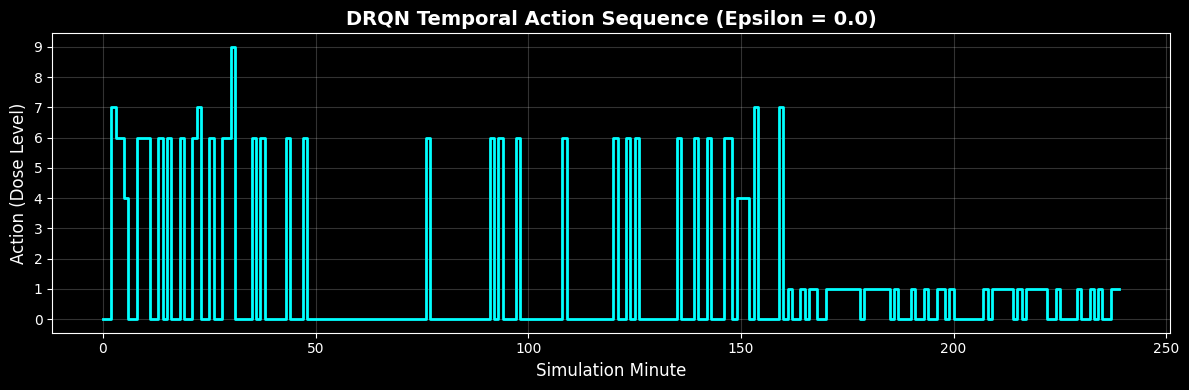

In [1]:
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os
from train import DRQN
from environment import PredictiveChemoEnv

class ToyChemoEnv(PredictiveChemoEnv):
    def __init__(self, schedule_parquet_path):
        super().__init__(schedule_parquet_path=schedule_parquet_path)

    def step(self, action):
        obs, reward, terminated, truncated, info = super().step(action)
        toy_reward = info['efficacy_reward'] # Unscaled for mapping distribution
        return obs, toy_reward, False, truncated, info

def run_temporal_evaluation():
    print(f"\n{'='*90}")
    print(f" TOY ENVIRONMENT: TEMPORAL POLICY ANALYSIS & BASELINE BENCHMARKING")
    print(f"{'='*90}")
    
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    env = ToyChemoEnv(schedule_parquet_path="datasets/1_week_sampling_schedule.parquet")
    
    # Load the trained model from the 200-episode pilot
    # (Assuming it was saved, or you can run this immediately after training in memory)
    policy_net = DRQN(input_dim=63, num_actions=10).to(device)
    ## Change this line in evaluate_toy_policy.py:
    try:
        # Update the filename to load the BEST checkpoint
        policy_net.load_state_dict(torch.load('models/toy_drqn_best.pt', map_location=device))
    except FileNotFoundError:
        print("[WARNING] 'models/toy_drqn_best.pt' not found. Ensure you saved the pilot model!")
        return

    # Define the strong baselines
    policies = {
        "Constant 1 (25%)": lambda t: 1,
        "Random": lambda t: env.action_space.sample(),
        "Alt 0 / 1": lambda t: 1 if (t // 10) % 2 == 0 else 0,
        "Alt 0 / 3": lambda t: 3 if (t // 10) % 2 == 0 else 0,
        "Alt 1 / 3": lambda t: 3 if (t // 10) % 2 == 0 else 1,
        "Trained DRQN": "DRQN_FLAG"
    }

    results = []
    drqn_actions = []

    for name, policy_func in policies.items():
        obs, _ = env.reset(seed=42)
        env.engine.gamma = 4.0
        env.engine.tumor_growth_rate = 0.006
        env.engine.drug['k_elim'] /= env.patient_clearance_factor
        
        hidden = None
        step_rewards, tumor_masses, phs, temps = [], [], [], []
        
        for step in range(240):
            if policy_func == "DRQN_FLAG":
                obs_tensor = torch.FloatTensor(obs).view(1, 1, -1).to(device)
                with torch.no_grad():
                    q_vals, hidden = policy_net(obs_tensor, hidden)
                    act = q_vals[0, 0, :].argmax().item()
                if name == "Trained DRQN":
                    drqn_actions.append(act)
            else:
                act = policy_func(step)
                
            obs, raw_reward, _, _, info = env.step(act)
            
            step_rewards.append(raw_reward) # Logging RAW reward
            tumor_masses.append(env.engine.tumor_mass)
            phs.append(info['real_ph'])
            temps.append(info['real_temp'])
            
        results.append({
            "Policy": name,
            "Raw_Return": np.sum(step_rewards),
            "Final_Mass": tumor_masses[-1],
            "Max_Temp": np.max(temps),
            "Min_pH": np.min(phs)
        })

    # Print the Benchmark Table
    df = pd.DataFrame(results)
    print(df.to_string(index=False, float_format="%9.4f"))
    print(f"{'='*90}\n")

    # Plot the Temporal Action Sequence for the DRQN
    plt.style.use('dark_background')
    plt.figure(figsize=(12, 4))
    plt.step(range(240), drqn_actions, where='post', color='cyan', linewidth=2)
    plt.title('DRQN Temporal Action Sequence (Epsilon = 0.0)', fontsize=14, fontweight='bold')
    plt.xlabel('Simulation Minute', fontsize=12)
    plt.ylabel('Action (Dose Level)', fontsize=12)
    plt.yticks(range(10))
    plt.grid(True, alpha=0.2)
    
    os.makedirs("results", exist_ok=True)
    save_path = "results/toy_drqn_temporal_sequence.png"
    plt.tight_layout()
    plt.savefig(save_path, dpi=300)
    print(f"[INFO] DRQN Temporal Sequence plot saved to {save_path}")

if __name__ == "__main__":
    run_temporal_evaluation()